#  Pretrained Word2Vec Embeddings for Sentiment Classification

**Goal:** classify IMDb movie reviews as *positive* or *negative* using a Keras model whose embedding layer is initialised with **pretrained Word2Vec vectors** (Google News) and kept **frozen**.

**Steps:**
1. Install Gensim, list the available embeddings and load Word2Vec
2. Load and prepare the IMDb dataset
3. Build the embedding matrix
4. Build, train and evaluate the Keras model

## Cell 1 – Install Gensim, explore the embeddings and load Word2Vec
- Installs the `gensim` library.
- `api.info()` shows every pretrained model that can be downloaded (we only print the names to keep the output short).
- `api.load("word2vec-google-news-300")` downloads Google's Word2Vec model (300-dimensional vectors, ~1.6 GB, so it takes a few minutes the first time).

In [1]:
# Install the gensim library (the "-q" flag keeps the output quiet)
!pip install -q gensim

# Import the gensim downloader and give it the short name "api"
import gensim.downloader as api

# api.info() returns a dictionary with all the available datasets/models
info = api.info()

# Print only the names of the available pretrained models
print("Available models:")
for name in info["models"].keys():
    print(" -", name)

# Load Google's pretrained Word2Vec model (trained on Google News)
# This returns a "KeyedVectors" object: word -> 300-dim vector
w2v = api.load("word2vec-google-news-300")

# Quick check: size of the vocabulary and the shape of one word vector
print("\nVocabulary size of Word2Vec:", len(w2v))
print("Vector shape for 'movie':", w2v["movie"].shape)

# Embedding size, read directly from the loaded model (= 300 for Google News Word2Vec)
EMBED_DIM = w2v.vector_size
print("Embedding size (EMBED_DIM):", EMBED_DIM)

Available models:
 - fasttext-wiki-news-subwords-300
 - conceptnet-numberbatch-17-06-300
 - word2vec-ruscorpora-300
 - word2vec-google-news-300
 - glove-wiki-gigaword-50
 - glove-wiki-gigaword-100
 - glove-wiki-gigaword-200
 - glove-wiki-gigaword-300
 - glove-twitter-25
 - glove-twitter-50
 - glove-twitter-100
 - glove-twitter-200
 - __testing_word2vec-matrix-synopsis
[==================================================] 100.0% 1662.8/1662.8MB downloaded

Vocabulary size of Word2Vec: 3000000
Vector shape for 'movie': (300,)
Embedding size (EMBED_DIM): 300


## Cell 2 – Load IMDb and build the word → index dictionary
- Loads the IMDb reviews (already converted to integers) and keeps the 10,000 most frequent words.
- Pads/cuts every review to 200 words so they all have the same length.
- **Word index:** `word2idx` gives each word its integer id (e.g. `"movie" → 20`) and `idx2word` is the reverse. Keras reserves ids 0–3 for special tokens, so real words start at `id + 3`.
- We print a few words with their index and **decode the first review** back to text to check that everything is consistent.
- ⚠️ `MAX_LEN = 200` is the **number of words per review**, while `EMBED_DIM = 300` is the **size of each word vector**. They are two different things.

In [2]:
import re
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

NUM_WORDS = 10000   # vocabulary size: only the 10,000 most frequent words are kept
MAX_LEN = 200       # number of WORDS per review (NOT the embedding size!)

# Load the dataset (reviews are lists of integers, labels: 0 = negative / 1 = positive)
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=NUM_WORDS)

# ---------- Word -> index dictionary ----------
word_index = imdb.get_word_index()                    # original dictionary (ids start at 1)
word2idx = {w: i + 3 for w, i in word_index.items()}  # shift by 3 (Keras reserved ids)
word2idx["<PAD>"] = 0      # padding
word2idx["<START>"] = 1    # start of a review
word2idx["<UNK>"] = 2      # unknown / rare word
word2idx["<UNUSED>"] = 3   # unused

# Reverse dictionary: index -> word
idx2word = {i: w for w, i in word2idx.items()}

# Show the index of some words
print("Index of some words:")
for w in ["the", "movie", "good", "bad", "great", "terrible"]:
    print(f"  {w:10s} -> {word2idx[w]}")

# Decode the first training review back into text
print("\nFirst review (decoded):")
print(" ".join(idx2word.get(i, "?") for i in x_train[0]))
print("Label:", "positive" if y_train[0] == 1 else "negative")

# Pad short reviews with 0s and cut long ones so all have length MAX_LEN
x_train = pad_sequences(x_train, maxlen=MAX_LEN)
x_test = pad_sequences(x_test, maxlen=MAX_LEN)

print("\nTrain shape:", x_train.shape)   # (25000, 200) -> 25000 reviews x 200 words
print("Test shape :", x_test.shape)      # (25000, 200)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Index of some words:
  the        -> 4
  movie      -> 20
  good       -> 52
  bad        -> 78
  great      -> 87
  terrible   -> 394

First review (decoded):
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that pla

## Cell 3 – Build the embedding matrix
- `imdb.get_word_index()` gives the dictionary **word → integer id** used by the dataset.
- Keras reserves ids 0–3 for special tokens (padding, start, unknown...), so real words start at `id + 3`.
- We create a matrix of shape `(NUM_WORDS, 300)`: **row i = Word2Vec vector of the word with id i**.
- Words that don't exist in Word2Vec keep a row of zeros.

In [3]:
# Matrix of zeros: one row per word of our vocabulary, EMBED_DIM (=300) columns
embedding_matrix = np.zeros((NUM_WORDS, EMBED_DIM))

found = 0  # counter of words found in the pretrained model

for word, idx in word2idx.items():
    # keep only the top words (idx < NUM_WORDS), skip special tokens (idx < 4)
    if 4 <= idx < NUM_WORDS and word in w2v:
        embedding_matrix[idx] = w2v[word]   # copy the pretrained vector
        found += 1

print("Embedding matrix shape:", embedding_matrix.shape)
print(f"Words found in the pretrained model: {found} / {NUM_WORDS - 4}")

Embedding matrix shape: (10000, 300)
Words found in the pretrained model: 9282 / 9996


## Cell 4 – Build, train and evaluate the model
**Architecture:**
1. `Embedding` layer initialised with our embedding matrix and **frozen** (`trainable=False`) so the Word2Vec vectors are not changed during training.
2. `GlobalAveragePooling1D` – averages the 200 word vectors into a single 300-dim vector per review.
3. `Dense(64, relu)` + `Dropout` – a small hidden layer (dropout reduces overfitting).
4. `Dense(1, sigmoid)` – outputs a probability (close to 1 = positive review).

> Note: in recent Keras versions the `weights=[matrix]` argument was removed, so we pass the matrix with `embeddings_initializer=Constant(matrix)`. It does exactly the same thing: the layer starts with our pretrained weights.

In [4]:
from tensorflow.keras import layers, models, initializers

# ---------- Build the model ----------
model = models.Sequential([
    # Embedding layer: initialised with Word2Vec vectors and FROZEN (trainable=False)
    layers.Embedding(
        input_dim=NUM_WORDS,                                        # vocabulary size
        output_dim=EMBED_DIM,                                       # size of each word vector
        embeddings_initializer=initializers.Constant(embedding_matrix),  # pretrained weights
        trainable=False,                                            # do not update the vectors
    ),
    layers.GlobalAveragePooling1D(),        # average all word vectors of the review
    layers.Dense(64, activation="relu"),    # hidden layer
    layers.Dropout(0.5),                    # randomly drop 50% of neurons to avoid overfitting
    layers.Dense(1, activation="sigmoid"),  # output: probability that the review is positive
])

# ---------- Compile the model ----------
model.compile(
    optimizer="adam",                # optimisation algorithm
    loss="binary_crossentropy",      # loss for a 2-class problem
    metrics=["accuracy"],            # metric to monitor
)

# Build the model with a known input shape so that summary() shows the parameters
model.build(input_shape=(None, MAX_LEN))
model.summary()   # the Embedding layer's parameters should appear as "non-trainable"

# ---------- Train the model ----------
history = model.fit(
    x_train, y_train,
    epochs=10,              # number of passes over the training data
    batch_size=128,         # number of reviews processed at once
    validation_split=0.2,   # 20% of training data is used for validation
    verbose=1,
)

# ---------- Evaluate on the test set ----------
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest accuracy: {test_acc:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 300)       │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 300)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        19,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,019,329 (11.52 MB)

 Trainable params: 19,329 (75.50 KB)

 Non-trainable params: 3,000,000 (11.44 MB)

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.6605 - loss: 0.6600 - val_accuracy: 0.7622 - val_loss: 0.6113
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7484 - loss: 0.5726 - val_accuracy: 0.8010 - val_loss: 0.5154
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7839 - loss: 0.5004 - val_accuracy: 0.8198 - val_loss: 0.4604
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.7977 - loss: 0.4619 - val_accuracy: 0.8228 - val_loss: 0.4320
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8082 - loss: 0.4406 - val_accuracy: 0.8280 - val_loss: 0.4146
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8120 - loss: 0.4283 - val_accuracy: 0.8276 - val_loss: 0.4061
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8165 - loss: 0.4191 - val_accuracy: 0.8302 - val_loss: 0.3985
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.8212 - loss: 0.4110 - val_accu

# **PLOTS :**

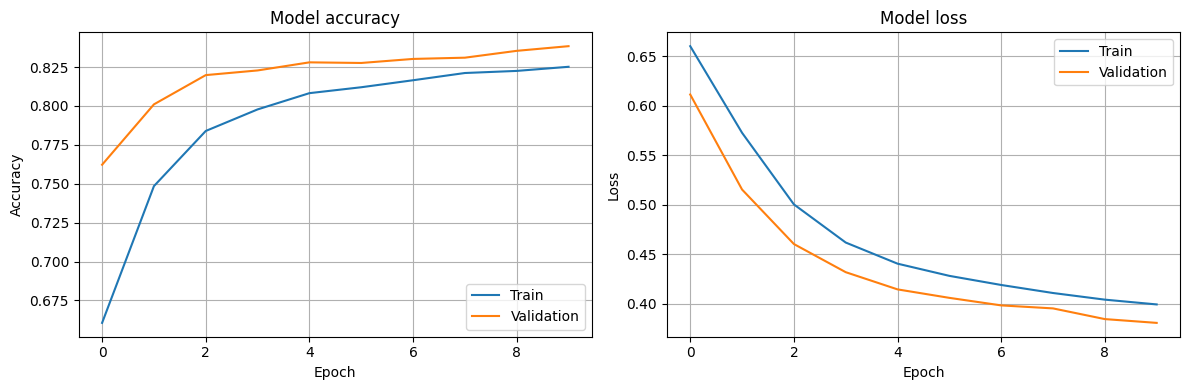

Test loss: 0.3844 | Test accuracy: 0.8336


In [5]:
# Create a figure with 2 plots side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ---- Accuracy plot ----
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# ---- Loss plot ----
axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# ---- Final evaluation on the test set ----
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

# **Some reviews Trial :**

In [6]:
def predict_review(text):
    """Return the probability that `text` is a positive review."""
    # 1) lowercase and remove punctuation
    text = re.sub(r"[^a-z0-9' ]", " ", text.lower())
    # 2) split into words
    words = text.split()
    # 3) words -> indices (words outside the vocabulary become <UNK> = 2)
    seq = [1]  # start token
    for w in words:
        idx = word2idx.get(w, 2)
        seq.append(idx if idx < NUM_WORDS else 2)
    # 4) pad / cut to MAX_LEN and predict
    seq = pad_sequences([seq], maxlen=MAX_LEN)
    return float(model.predict(seq, verbose=0)[0][0])

# ---------- Our own sentences ----------
my_reviews = [
    "This movie was great, the acting was wonderful and I loved the story",
    "An amazing and beautiful film, I highly recommend it",
    "Terrible movie, boring plot and awful acting, a complete waste of time",
    "I hated it, the worst film I have ever seen",
    "good",
    "bad",
]

print("=== Our own reviews ===")
for r in my_reviews:
    p = predict_review(r)
    print(f"{'POSITIVE' if p > 0.5 else 'NEGATIVE'} ({p:.2f}) -> {r}")

# ---------- 5 real test reviews: prediction vs true label ----------
print("\n=== 5 reviews from the test set ===")
preds = model.predict(x_test[:5], verbose=0).ravel()
for i in range(5):
    predicted = "POSITIVE" if preds[i] > 0.5 else "NEGATIVE"
    real = "POSITIVE" if y_test[i] == 1 else "NEGATIVE"
    print(f"Review {i}: predicted = {predicted} ({preds[i]:.2f}) | real = {real} | {'OK' if predicted == real else 'WRONG'}")

=== Our own reviews ===
POSITIVE (0.77) -> This movie was great, the acting was wonderful and I loved the story
POSITIVE (0.78) -> An amazing and beautiful film, I highly recommend it
NEGATIVE (0.15) -> Terrible movie, boring plot and awful acting, a complete waste of time
NEGATIVE (0.49) -> I hated it, the worst film I have ever seen
POSITIVE (0.56) -> good
NEGATIVE (0.45) -> bad

=== 5 reviews from the test set ===
Review 0: predicted = NEGATIVE (0.36) | real = NEGATIVE | OK
Review 1: predicted = POSITIVE (0.98) | real = POSITIVE | OK
Review 2: predicted = POSITIVE (0.51) | real = POSITIVE | OK
Review 3: predicted = NEGATIVE (0.19) | real = NEGATIVE | OK
Review 4: predicted = POSITIVE (0.76) | real = POSITIVE | OK


# **Dashboard :**

In [7]:

# ==========================================
# IMDb SENTIMENT ANALYZER - GRADIO INTERFACE
# ==========================================

# Install Gradio
!pip install -q gradio

# Import Gradio
import gradio as gr

# ---------- Color palette ----------
BLACK = "#000000"
BLUE = "#14213D"
ORANGE = "#FCA311"
GREY = "#E5E5E5"
LIGHT_GREY = "#F2F2F2"
WHITE = "#FFFFFF"


# ---------- Prediction function ----------
def analyze_review(review):

    # Check if the user entered a review
    if not review.strip():
        return """
        <div class="result-card">
            Please enter a movie review first.
        </div>
        """

    # Use our already trained model
    probability = predict_review(review)

    # Determine the sentiment
    if probability >= 0.5:
        sentiment = "POSITIVE"
        label = 1
        confidence = probability * 100
        result_color = ORANGE
        result_icon = "😊"

    else:
        sentiment = "NEGATIVE"
        label = 0
        confidence = (1 - probability) * 100
        result_color = BLUE
        result_icon = "😞"

    # Return the prediction as a styled HTML result
    return f"""
    <div class="result-card">

        <div class="result-icon">{result_icon}</div>

        <h2 style="color: {result_color};">
            {sentiment}
        </h2>

        <p class="result-label">
            Predicted Label: {label}
        </p>

        <div class="confidence-title">
            Confidence Score
        </div>

        <div class="progress-background">
            <div class="progress-fill"
                 style="width: {confidence}%;
                        background-color: {result_color};">
            </div>
        </div>

        <h3>{confidence:.2f}%</h3>

    </div>
    """


# ---------- Custom CSS ----------
custom_css = """

.gradio-container {
    background-color: #F2F2F2 !important;
}

.main-title {
    text-align: center;
    color: #14213D;
    font-size: 38px;
    font-weight: bold;
}

.subtitle {
    text-align: center;
    color: #555555;
    font-size: 16px;
}

.input-box textarea {
    background-color: #FFFFFF !important;
    border: 2px solid #E5E5E5 !important;
    border-radius: 12px !important;
    color: #000000 !important;
}

.analyze-btn {
    background-color: #FCA311 !important;
    color: #000000 !important;
    border: none !important;
    border-radius: 10px !important;
    font-weight: bold !important;
}

.result-card {
    background-color: #FFFFFF;
    border: 2px solid #E5E5E5;
    border-radius: 15px;
    padding: 25px;
    text-align: center;
    margin-top: 15px;
}

.result-icon {
    font-size: 45px;
}

.result-label {
    color: #666666;
    font-size: 14px;
}

.confidence-title {
    color: #14213D;
    font-weight: bold;
    margin-top: 20px;
}

.progress-background {
    background-color: #E5E5E5;
    height: 12px;
    border-radius: 10px;
    overflow: hidden;
}

.progress-fill {
    height: 12px;
    border-radius: 10px;
}

"""


# ---------- Build the interface ----------
with gr.Blocks(
    theme=gr.themes.Base(
        primary_hue="orange",
        neutral_hue="slate"
    ),
    css=custom_css
) as demo:

    # Application title
    gr.HTML("""
        <h1 class="main-title">
            IMDb Sentiment Analyzer
        </h1>

        <p class="subtitle">
            Analyze movie reviews using Word2Vec
            and Deep Learning.
        </p>
    """)

    # Review input
    review_input = gr.Textbox(
        label="Enter Your Movie Review",
        placeholder="Write your movie review here...",
        lines=5,
        elem_classes=["input-box"]
    )

    # Analyze button
    analyze_button = gr.Button(
        "Analyze Review",
        elem_classes=["analyze-btn"]
    )

    # Prediction output
    result_output = gr.HTML()

    # Connect button to prediction function
    analyze_button.click(
        fn=analyze_review,
        inputs=review_input,
        outputs=result_output
    )

    # Allow Enter via keyboard? The button remains the main action.
    # Example reviews
    gr.Examples(
        examples=[
            ["This movie was absolutely amazing. I loved every minute of it!"],
            ["Terrible movie, boring story and awful acting."],
            ["The film was wonderful and the actors did a great job."]
        ],
        inputs=review_input
    )


# ---------- Launch the application ----------
demo.launch(share=True, debug=False)


/tmp/ipykernel_19067/1157697181.py:155: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3dfaca7924134d1812.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
